#==================================================

## import library

In [ ]:
import os
import pandas as pd
import numpy as np

import os.path

import seaborn as sns
import matplotlib.pyplot as plt


#==================================================

## Def: count_varType()

In [ ]:
def count_varType(_df):
    print("=== DEF: count_varType()")
    _return = None

    for _k in [None, 0, 1]:
        if _k is None:
            _des = _df['varType'].value_counts().to_frame(name='count')
            _k = 'All'
        else:
            _des = _df.loc[_df['clnSig2'] == _k, 'varType'].value_counts().to_frame(name='count')
            _des[f'{_k}_ratio1'] = (_des['count'] / _df[_df['clnSig2']==_k].shape[0]) * 100

        _des[f'{_k}_ratio'] = (_des['count'] / _df.shape[0]) * 100
        _des.rename(columns={'count': f'{_k}_count'}, inplace=True)
        _des.reset_index(inplace=True)

        if _return is None:
            _return = _des
        else:
            _return = pd.merge(_return, _des, on='varType', how='outer')

    _return = _return.fillna(0)
    _total = ['total'] + list(_return.select_dtypes(include=['number']).sum().values)
    _return.loc[_return.shape[0]] = _total

    return(_return)

## Def: extract_tool_name()

In [ ]:
def extract_tool_name(_colLists, _sCol, _eCol):
    _chg_name = {'CADD_raw': 'CADD', 'fathmm-XF_coding': 'FATHMM-XF', 'fathmm-MKL_coding': 'FATHMM-MKL',
                'Polyphen2_HDIV':'PolyPhen2_HDiv', 'Polyphen2_HVAR':'PolyPhen2_HVar',
                 'Eigen-raw_coding':'Eigen','VARITY_R':'VARITY'}

    _results = []
    _results.append({'tool': 'PRP', 'type': 'score', 'col': 'PRP_score'})
    _results.append({'tool': 'PRP', 'type': 'rankscore', 'col': 'PRP_rankscore'})
    _results.append({'tool': 'PRP', 'type': 'pred', 'col': 'PRP_pred'})

    #for i in range(27,104):
    for _i in range(_sCol, _eCol):
        _col = _colLists[_i]
        _type = ''

        if _col.startswith('Eigen-PC'):
            print(f"*** Unprocessed column: {_col}")
            continue

        if _col.endswith('_score'):
            _col = _col.replace('_score', '')
            _type = 'score'
        elif _col.endswith('_raw') or _col.endswith('_coding'):
            _type = 'score'
        elif _col.endswith('_pred'):
            _col = _col.replace('_pred', '')
            _type = 'pred'
        elif _col.endswith('_converted_rankscore') or _col.endswith('_rankscore'):
            _col = _col.replace('_converted_rankscore', '').replace('_rankscore', '')
            _type = 'rankscore'
        else:
            print(f"*** Unprocessed column: {_col}")
            continue

        if _col in _chg_name.keys():
            _col = _chg_name[_col]

        _results.append({'tool': _col, 'type': _type, 'col': _colLists[_i]})

    _df = pd.DataFrame(_results)
    _df = _df.pivot(index='tool', columns='type', values='col').reset_index()

    _cat = {'PRP':0, 'ClinPred':2, 'MetaRNN':2, 'REVEL':2, 'gMVP':1, 'MVP':2, 'CADD':2, 'DEOGEN2':2,
       'MetaSVM':2, 'MetaLR':2, 'MutPred':2, 'VEST4':1, 'M-CAP':2, 'MutationAssessor':1, 'PROVEAN':1,
       'FATHMM':1, 'PolyPhen2_HVar':1, 'SIFT4G':1, 'SIFT':1, 'PolyPhen2_HDiv':1, 'LIST-S2':1,
       'PrimateAI':1, 'MPC':2, 'DANN':2, 'FATHMM-MKL':1, 'FATHMM-XF':1, 'LRT' : 1, 'VARITY':2,
            'GenoCanyon':1,'Eigen':2}

    _cutoffs = {'PRP_score':0.5,
        'SIFT_score':0.05,#0.051,
                'SIFT4G_score':0.049, #0.05,
                'Polyphen2_HDIV_score':0.452, 'Polyphen2_HVAR_score':0.446,
        'MutationAssessor_score':1.935, 'FATHMM_score':-1.5,#-1.49,
                'PROVEAN_score':-2.5, 'MetaSVM_score':0,
        'MetaLR_score':0.4999, 'MetaRNN_score':0.5, 'M-CAP_score':0.025, 'PrimateAI_score':0.803,
        'DEOGEN2_score':0.5, 'ClinPred_score':0.5, 'LIST-S2_score':0.85,
        'fathmm-MKL_coding_score':0.5,'fathmm-XF_coding_score':0.5,
        'VEST4_score':0.5,'MutPred_score':0.5, 'MVP_score':0.7,
        #'CADD_raw':20, 'DANN_score':0.99,'REVEL_score':0.4,
        'CADD_raw':0, 'DANN_score':0.5,'REVEL_score':0.5,
        'gMVP_score':0.5, 'MPC_score':0.5, 'VARITY_R_score':0.5,
        'Eigen-raw_coding':0.5, 'GenoCanyon_score':0.5,
    }

    _minus = {'SIFT':1, 'SIFT4G':1, 'FATHMM':1, 'PROVEAN':1}

    _df['cat'] = 0
    _df['minus'] = 0
    for _idx in _df.index:
        if _df.loc[_idx, 'tool'] in _cat:
            _df.loc[_idx,'cat'] = _cat[_df.loc[_idx, 'tool']]
        else:
            print(f"*** No(cat): {_df.loc[_idx, 'tool']}")

        if _df.loc[_idx, 'score'] in _cutoffs:
            _df.loc[_idx,'cutoff'] = _cutoffs[_df.loc[_idx, 'score']]
        else:
            print(f"*** No(cutoff): {_df.loc[_idx, 'tool']}")

        if _df.loc[_idx, 'tool'] in _minus:
            _df.loc[_idx,'minus'] = _minus[_df.loc[_idx, 'tool']]
            print(f"*** Yes(minus): {_df.loc[_idx, 'tool']}")

    _df['cat'] = _df['cat'].astype('category')
    _df = _df[['tool','cat','cutoff','minus','score','rankscore','pred']].sort_values(by=['cat','tool']).reset_index(drop=True)
    return (_df)

## Def: compare_performance()

In [ ]:
def compare_performance(y, y_pred, y_prob, cutoff, _minus):
    from sklearn.preprocessing import Binarizer
    from sklearn.metrics import precision_recall_curve,classification_report
    from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix, roc_auc_score
    from sklearn.metrics import roc_curve, auc, matthews_corrcoef, average_precision_score
    from scipy.stats import gmean #기하평균
    from sklearn.metrics import confusion_matrix

    # Binarize the probabilities using the cutoff
    binarizer = Binarizer(threshold = cutoff)
    thres_pred = binarizer.fit_transform(y_prob)

    if _minus == 1:
        thres_pred = 1 - thres_pred
        y_prob = -y_prob
    # Calculate confusion matrix and metrics
    tn, fp, fn, tp = confusion_matrix(y, thres_pred).ravel()

    # Handle edge cases where denominators may be zero
    def safe_divide(n, d):
        return n / d if d > 0 else 0.0

    if y_pred is not None:
        comparison = y_pred == thres_pred
        diff_idx = np.where(y_pred != thres_pred)[0]
        print("Num(all)=",len(y),"\tNum(eq)=", sum(comparison), "\tNum(diff)=",len(diff_idx))
        print(y[diff_idx], y_pred[diff_idx], thres_pred[diff_idx],y_prob[diff_idx])
    else:
        print("No Pred")
    #auc = roc_auc_score(y, thres_pred)
    #auprc = average_precision_score(y, thres_pred)

    metrics = {
        'Cutoff' : cutoff,
        'Accuracy': accuracy_score(y, thres_pred),
        'Precision': precision_score(y, thres_pred), #tp/(tp+fp)
        'Recall': recall_score(y, thres_pred), #tp/(tp+fn) sensitivity
        'F1-score': f1_score(y, thres_pred), # 2*precision*recall / (precision+recall)
        'MCC': matthews_corrcoef(y, thres_pred),
        'AUC': roc_auc_score(y, y_prob),
        'AUPRC': average_precision_score(y, y_prob),
        'Specificity': safe_divide(tn, tn + fp),
        'G-mean': gmean([recall_score(y, thres_pred), safe_divide(tn, tn + fp)]), #math.sqrt(recall * specificity)
        'PPV': safe_divide(tp, tp + fp),
        'NPV': safe_divide(tn, tn + fn),
        'FNR': safe_divide(fn, tp + fn),
        'FPR': safe_divide(fp, tn + fp),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp
    }

    # Prepare the result DataFrame
    _temp = pd.DataFrame([metrics])

    return (round(_temp,4), thres_pred)

## Def calc_AF_performance()

In [ ]:
def calc_AF_performance(_df_score,_df_tools,_af, _clnSig, _test, png_fold):
    # cufoff가 없으면 계산 안함
    # score를 이용

    if _af >0:
        _df_score = _df_score[(_df_score['gnomAD_exom_v2_AF']<_af) | (_df_score['gnomAD_exom_v2_AF'].isna())].reset_index(drop=True)
    elif _af == 0:
        _df_score = _df_score[_df_score['gnomAD_exom_v2_AF'].isna()].reset_index(drop=True)
    elif _af < 0:
        _df_score = _df_score[(_df_score['gnomAD_exom_v2_AF']< -(_af))].reset_index(drop=True)

    print(f"!!! AF({_af} : {_df_score.shape[0]})")

    _df_pred = pd.DataFrame()
    _df_pred['Disease'] = _df_score[_clnSig]
    _df_pred['varType'] = _df_score['varType']

    _result = pd.DataFrame(columns=['Name','Cutoff','cat','AUC','AUPRC','Accuracy','F1-score','MCC',
                                    'Precision','Recall','Specificity','G-mean'])

    #for _idx in _df_tools.index:
     #   _tool = _df_tools.loc[_idx, 'tool']
     #   _pred = _df_tools.loc[_idx, 'pred']
      #  _score = _df_tools.loc[_idx, 'score']
       # _cutoff = _df_tools.loc[_idx, 'cutoff']
       # _minus = _df_tools.loc[_idx, 'minus']
       # _cat = _df_tools.loc[_idx, 'cat']
    for _idx, _row in _df_tools.iterrows():
        _tool = _row['tool']
        _pred = _row['pred']
        _score = _row['score']
        _cutoff = _row['cutoff']
        _minus = _row['minus']
        _cat = _row['cat']

        #if _tool not in ['PRP']:
         #   continue

        print("!!!: ",_idx, _tool, _cutoff, _minus)

        if pd.isna(_cutoff):
            print("\tNo(cutoff):", _idx, _tool)
            continue

        _list = []
        for _name in [_clnSig, _pred, _score]:
            if pd.notna(_name):
                _list.append(_name)

        _tmp = _df_score[_list].copy()
        _tmp = _tmp.dropna(subset=[_score])
        _remain_idx = _tmp.index
        _tmp = _tmp.reset_index(drop=True)

        y = _tmp[_clnSig].values.reshape(-1,1)
        y_prob = _tmp[_score].values.reshape(-1,1)
        y_pred = None
        if pd.notna(_pred):
            y_pred = _tmp[_pred].values.reshape(-1,1)
        if len(y_prob) == 0:
            continue

        # DEF : compare_performance()
        if len(np.unique(y)) == 1:
            continue

        _temp, thres_pred = compare_performance(y, y_pred, y_prob, _cutoff, _minus)
        _temp['Name'] = [_tool]
        _temp['Cutoff'] = [_cutoff]
        _temp['cat'] = [_cat]
        _temp['N'] = _tmp.shape[0]
        _temp['N_0'] = _df_score.loc[_df_score[_clnSig]==0, _score].notna().sum()
        _temp['N_1'] = _df_score.loc[_df_score[_clnSig]==1, _score].notna().sum()
        _temp['N_miss'] = _df_score[_score].isna().sum()
        _temp['N_miss_0'] = _df_score.loc[_df_score[_clnSig]==0, _score].isna().sum()
        _temp['N_miss_1'] = _df_score.loc[_df_score[_clnSig]==1, _score].isna().sum()
        _temp['Missing Rate'] = [0]

        if _temp['N_miss'].values[0] > 0:
            _temp['Missing Rate'] = [(_temp['N_miss'].values[0] / (_temp['N'].values[0] + _temp['N_miss'].values[0]))*100]

        _result = pd.concat([_result, _temp], axis=0, ignore_index = True)
        _df_pred.loc[_remain_idx, _tool] = thres_pred
        _tmp['pred'] = thres_pred
        _tmp['pred'] = _tmp['pred'].astype('int').astype('object')

        if _af != 1:
            continue
        elif png_fold =='':
            continue

    _df_pred = _df_pred.fillna(-9)
    for col in _df_pred.columns:
        if col != 'varType':
            _df_pred[col] = _df_pred[col].astype('int64').astype('category')

    return _df_pred, _result

#==================================================

## Fig2: heatmap

In [ ]:
def figure_heatmap(_df, _colL, _chgColL, _orderColL, _method, save_png):
    _round = 3
    if _colL:
        _df = _df[_colL]

    if _chgColL:
        _df = _df.rename(columns=_chgColL)

    if _orderColL:
        _df = _df[_orderColL]

    _cor = _df.corr(method = _method)
    _df_cor = pd.DataFrame(_cor)

    plt.figure(figsize=(22, 18), dpi=150)  # 이미지 크기 조절
    #sns.heatmap(cor, annot=False, fmt=".2f", cmap='coolwarm', cbar=True)
    #sns.heatmap(cor, annot=False, fmt=".2f", cmap='viridis', cbar=True)
    ax=sns.heatmap(_cor, annot=False, fmt=".2f", cmap='vlag', cbar=True,
                cbar_kws={'label': f'{_method} correlation coefficient'})
    cbar = plt.gcf().axes[-1]  # 색상 바를 나타내는 축 가져오기
    cbar.yaxis.label.set_size(24)
    cbar.tick_params(labelsize=16)

    ax.set_xticklabels(ax.get_xticklabels(), fontsize=20)
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=20)
    #plt.title('Correlation Matrix Heatmap', size=20)

    if save_png:
        print("!!! png: ", save_png)
        plt.savefig(save_png, dpi=150)
    else:
        print("!!! png: No Save")
    plt.show()

    return _df_cor

!!! png: No Save


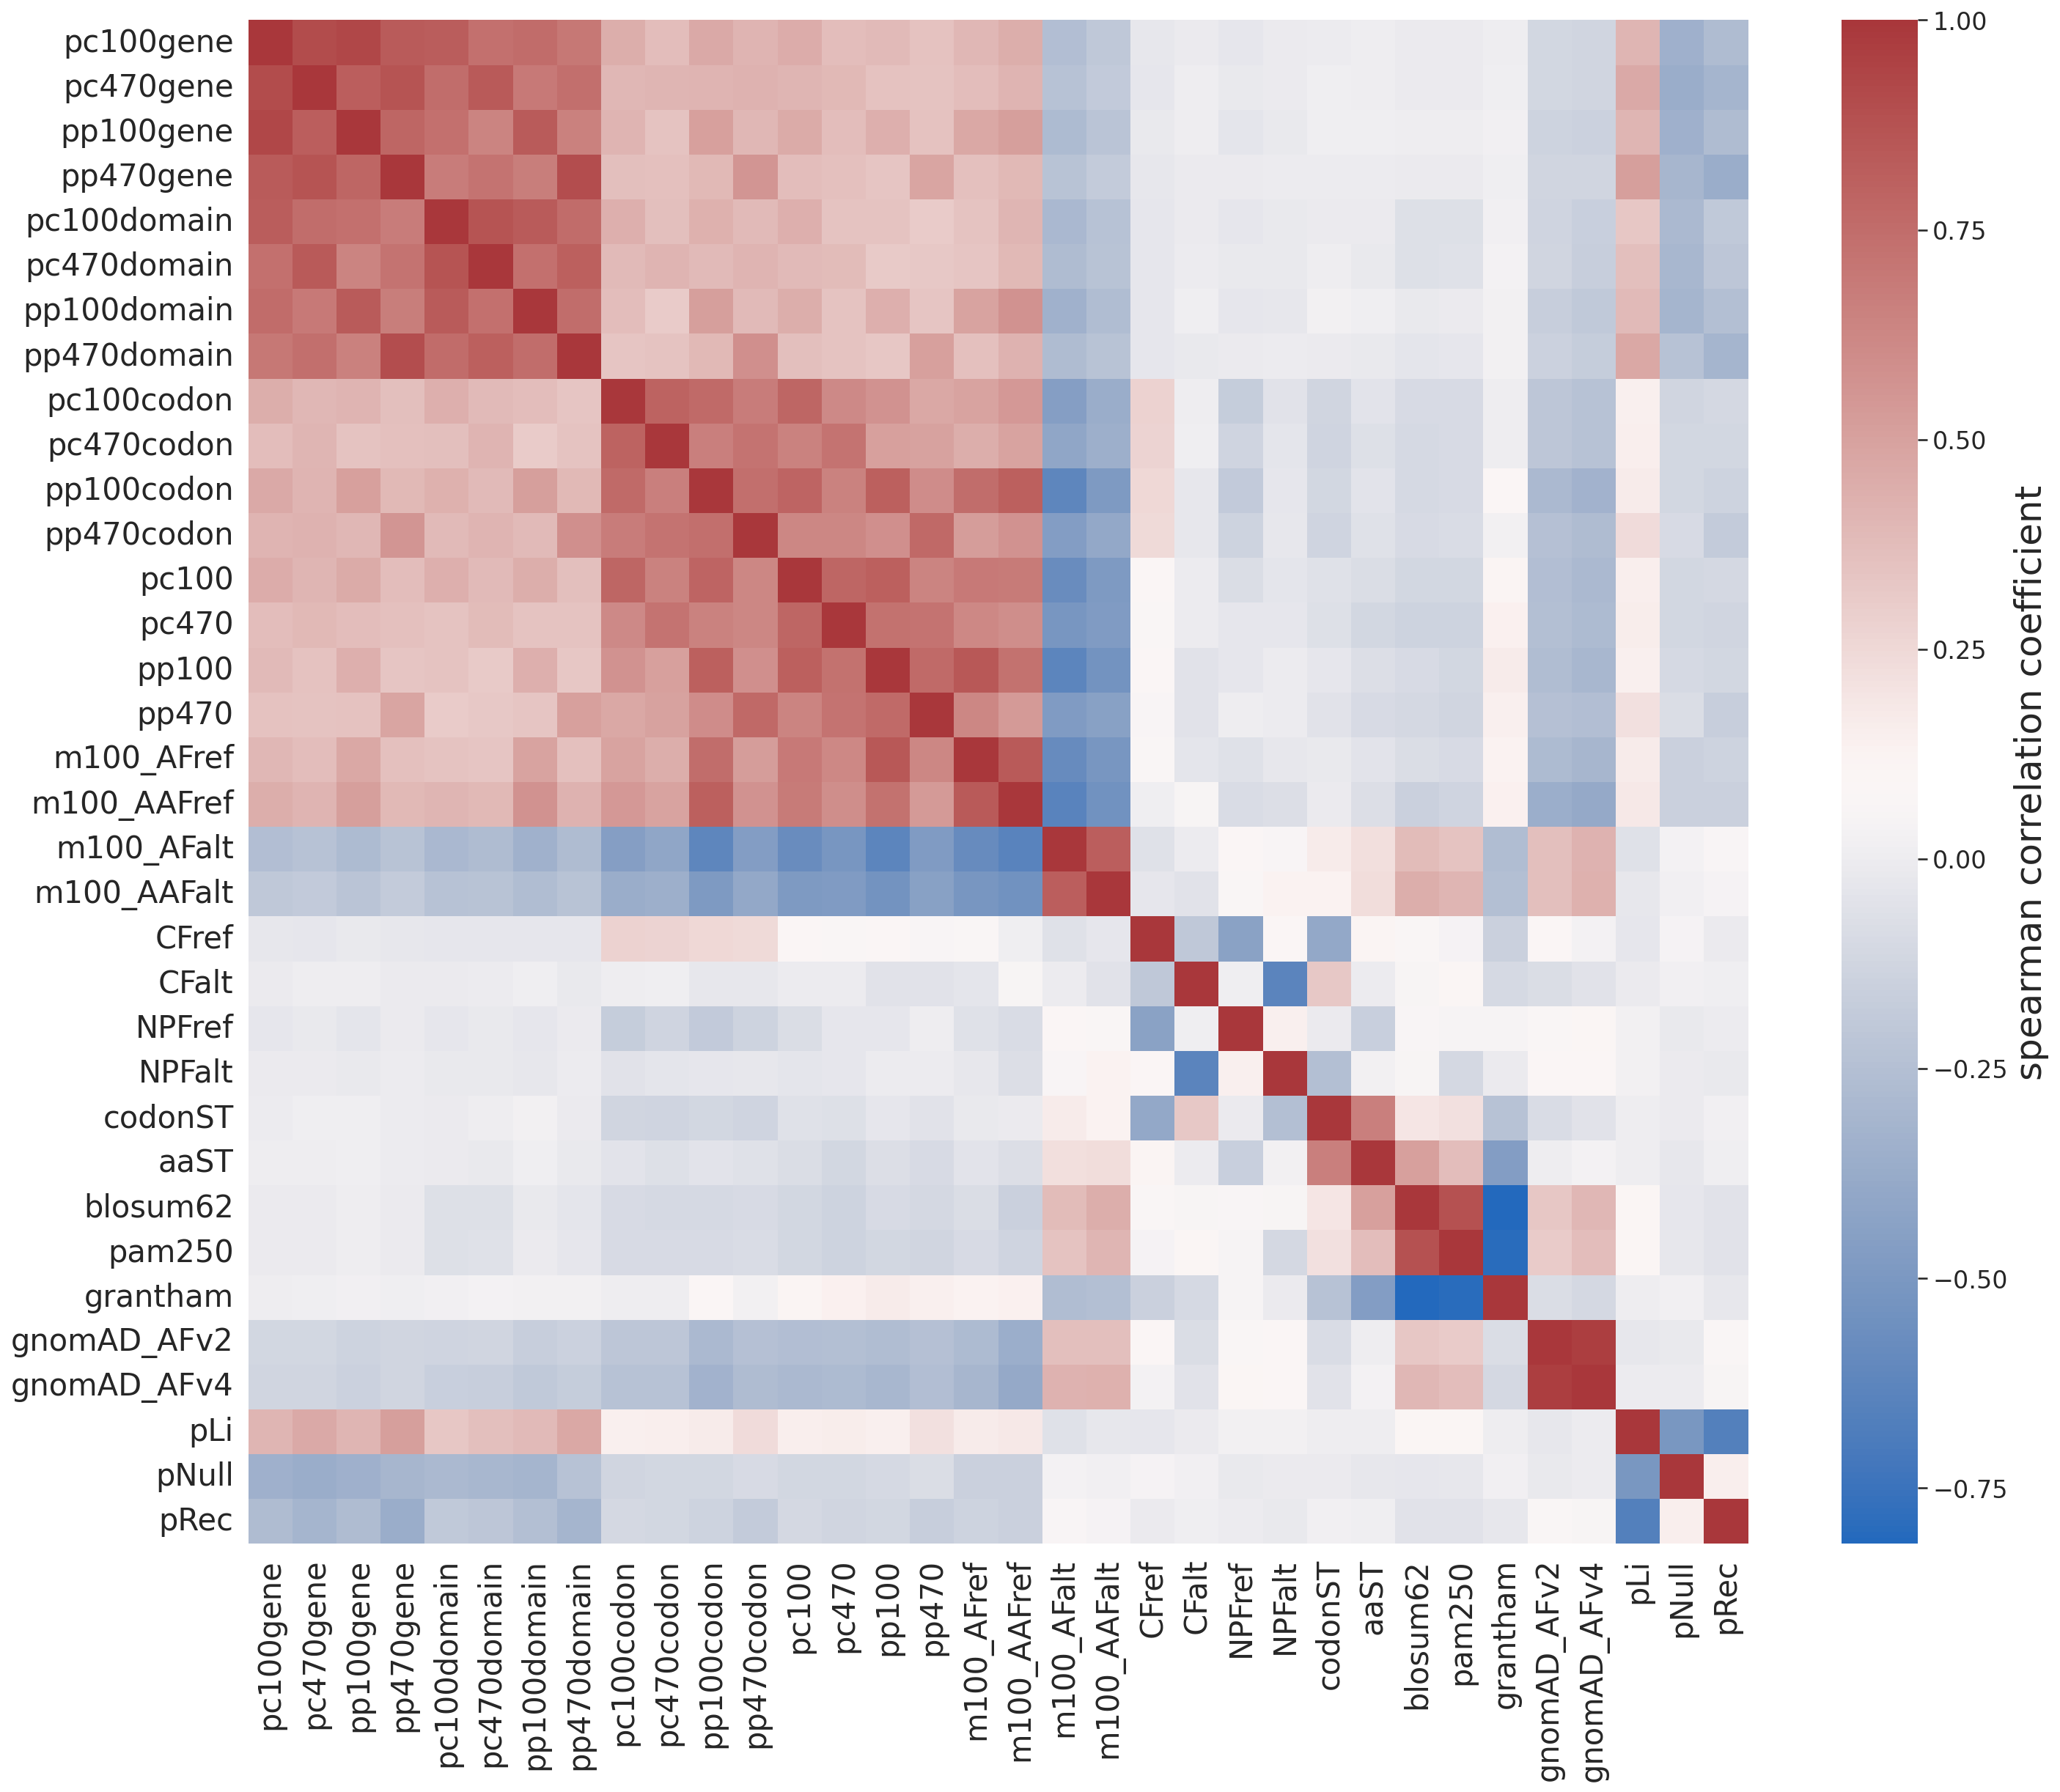

#==================================================

## Fig3

### radar plot : model comparison

In [ ]:
_title='Training'
_model= ['XGBoost', 'LightGBM', 'CatBoost', 'TabNet', 'DNN',]
_theta=['AUC', 'AUPRC', 'Accuracy', 'F1-score', 'MCC', 'Precision', 'Recall', 'Specificity']

model_xgb = [0.9983, 0.9985, 0.9833, 0.9839, 0.9666, 0.9849, 0.9829, 0.9838]
model_lgb = [0.9978, 0.9980, 0.9837, 0.9843, 0.9674, 0.9847, 0.9839, 0.9835]
model_cat = [0.9978, 0.9977, 0.9811, 0.9818, 0.9622, 0.9825, 0.9810, 0.9812]
model_tab = [0.9855, 0.9875, 0.9457, 0.9515, 0.8904, 0.9367, 0.9669, 0.9197]
model_dnn = [0.9675, 0.9730, 0.9005, 0.9092, 0.7992, 0.9149, 0.9035, 0.8967]


import plotly.express as px
_color = ['#EF553B','#00CC96','#AB63FA', '#FFA15A','#19D3F3',]

df = pd.DataFrame()

for i, values in enumerate([model_xgb, model_lgb, model_cat, model_tab, model_dnn,]):
    _tmp = pd.DataFrame(dict(r = values, theta= _theta))
    _tmp['ML Model'] = _model[i]
    df = pd.concat([df,_tmp], axis=0)

fig = px.line_polar(df, r='r', color='ML Model', theta='theta', line_close=True,
                    color_discrete_sequence=_color,
                    #color_discrete_sequence=px.colors.qualitative.D3,
                    )
fig.update_layout(#template=None,
    polar = dict(radialaxis = dict(range=[0, 1], showticklabels=True, dtick=0.1),
                 angularaxis=dict(tickfont=dict(size=16)),)
    )
fig.update_polars(sector=[-270,90], radialaxis_ticks='')
fig.update_layout(title_text='A',
                  title_x = 0.05, title_y = 0.95, title_font_size = 16,
                 title_xanchor = "center", title_yanchor = "middle")
fig.update_layout(width=530,height=440,
                  margin_l=60, margin_r=80,
                  margin_b=30,margin_t=30)
#title
#fig.update_layout(title=_title,
#                title_x = 0.45, title_y = 0.45, title_font_size = 24,
#                 title_xanchor = "center", title_yanchor = "middle")

#fig.show()
#png_fold = '/content/drive/MyDrive/Colab Notebooks/2024_model/clinvar'
#_save_png = png_fold + "/"+ f'radar_compare_model.png'
_save_png = fold_here + f'/radar_compare_model.png'
print("!!! Save(PMG): ", _save_png)
#fig.write_image(_save_png, scale=3)
fig.show()

!!! Save(PMG):  /content/drive/MyDrive/Colab Notebooks/2024_model/radar_compare_model.png


### radar plot : dataset comparison

In [ ]:
_model= ['Training', 'Test1', 'Test2', 'Test3']
_theta=['AUC', 'AUPRC', 'Accuracy', 'F1-score', 'MCC', 'Precision', 'Recall', 'Specificity']

training = [0.9983, 0.9985, 0.9833, 0.9839, 0.9666, 0.9849, 0.9829, 0.9838]
test1 = [0.9993, 0.9995, 0.9902, 0.9915, 0.9800, 0.9926, 0.9905, 0.9899]
test2 = [0.9958, 0.9949, 0.9848, 0.9854, 0.9697, 0.9923, 0.9785, 0.9917]
test3 = [0.9914, 0.9984, 0.9858, 0.9916, 0.9451, 0.9916, 0.9916, 0.9535]

import plotly.express as px
#'#636EFA', '#EF553B', '#00CC96','#AB63FA', '#FFA15A', '#19D3F3','#FF6692', '#B6E880', '#FF97FF','#FECB52'
_color = ['#EF553B','#00CC96','#AB63FA', '#FFA15A',]
legend_name = 'Dataset'
df = pd.DataFrame()
for i, values in enumerate([training, test1, test2, test3]):
    _tmp = pd.DataFrame(dict(r = values, theta= _theta))
    _tmp[legend_name] = _model[i]
    df = pd.concat([df,_tmp], axis=0)

fig = px.line_polar(df, r='r', color=legend_name, theta='theta', line_close=True,
                    color_discrete_sequence=_color,
                    #color_discrete_sequence=px.colors.qualitative.Light24,
                    )
fig.update_layout(#template=None,
    polar = dict(radialaxis = dict(range=[0, 1], showticklabels=True, dtick=0.1),
                 angularaxis=dict(tickfont=dict(size=16)),)
    )
fig.update_polars(sector=[-270,90], radialaxis_ticks='')
fig.update_layout(title_text='B',
                  title_x = 0.05, title_y = 0.95, title_font_size = 16,
                 title_xanchor = "center", title_yanchor = "middle")
fig.update_layout(width=530,height=440,
                    margin_l=60, margin_r=80,
                    margin_b=30,margin_t=30)
#fig.show()
#png_fold = '/content/drive/MyDrive/Colab Notebooks/2024_model/clinvar'
#_save_png = png_fold + "/"+ f'radar_compare_model.png'
_save_png = fold_here + f'/radar_compare_dataset.png'
#print("!!! png: ", _save_png)
#fig.write_image(_save_png, scale=3)
fig.show()

#==================================================

## Fig 4,5,6

### ROC

In [ ]:
def plot_roc_pr_curve_multi(_df_tool, _df_result, _df_score, _clnSig, _key, save_png, ):
    from sklearn.metrics import roc_curve, auc, average_precision_score, precision_recall_curve

    _info = {'AUPRC_x':'Recall', 'AUPRC_y':'Precision', 'AUPRC_title':'Precision-Recall Curve','AUPRC_loc':'lower left',
             'AUC_x':'False Positive Rate', 'AUC_y':'True Positive Rate', 'AUC_title':'ROC Curve','AUC_loc':'lower right',
             }
    _notL = ['PolyPhen2_HDiv','SIFT4G','FATHMM-XF','FATHMM-MKL','GenoCanyon',
             'Eigen','MPC','DANN',]
    fig, ax = plt.subplots(figsize=(4, 4), dpi=150)
    #fig, ax = plt.subplots( dpi=150)

    _df_result = _df_result.sort_values(_key, ascending=False).reset_index(drop=True)
    for _i, _row in _df_result.iterrows():
        _tool = _row['Name']
        _value = _row[_key]

        _row1 = _df_tool[_df_tool['tool'] == _tool]
        _score = _row1['score'].values[0]
        _minus = _row1['minus'].values[0]

        if _tool in _notL:
            continue

        _tmp = _df_score[[_clnSig, _score]].copy().dropna(subset=[_score]).reset_index(drop=True)
        #print("!!! ",_i, _tool, _score, _key, _value,
        #      _tmp[_tmp[_clnSig]==0][_score].shape, _tmp[_tmp[_clnSig]==1][_score].shape,)

        y = _tmp[_clnSig].values.reshape(-1,1)
        y_prob = _tmp[_score].values.reshape(-1,1)
        if _minus:
            y_prob = -y_prob

        _x, _y = None, None
        if _key == 'AUPRC':
            precision, recall, cut = precision_recall_curve(y, y_prob)
            _x = recall
            _y = precision
        elif _key == 'AUC':
            fpr, tpr, cut = roc_curve(y, y_prob)
            _x = fpr
            _y = tpr

        #print("\t",auc(_x,_y))

        if _tool == 'PRP':
            ax.plot(_x,_y, label=f'{_tool} ({_value:.4f})', linewidth = 1, color='red')
        else:
            if _tool == 'PolyPhen2_HVar':
                _tool = 'PolyPhen2'
            ax.plot(_x,_y, label=f'{_tool} ({_value:.4f})', linewidth = 1)

    if _key == 'AUC':
        ax.plot([0, 1], [0, 1], linestyle='--', linewidth=0.5,color='lightgray' )

    ax.set_xlabel(_info[f'{_key}_x'], fontsize=8)
    ax.set_ylabel(_info[f'{_key}_y'], fontsize=8)
    #ax.set_title(_info[f'{_key}_title'], fontsize=12)
    ax.tick_params(labelsize=6)
    ax.grid(linestyle='--', linewidth=0.5, )#axis='y', )
    ax.legend(fontsize=6, loc=_info[f'{_key}_loc'], frameon=False, ncol=2,)

    # 축 범위 설정
    ax.set_xlim(-0.01, 1.01)  # x축 범위: 0~1
    ax.set_ylim(-0.01, 1.01)  # y축 범위: 0~1
    ax.set_aspect('equal', adjustable='box')  # 축 비율을 정사각형으로 맞춤

    plt.tight_layout()
    plt.show()
    if save_png:
        plt.savefig(save_png, dpi=150)
        #plt.show()
        print("!!! save:", save_png)


clinvar2


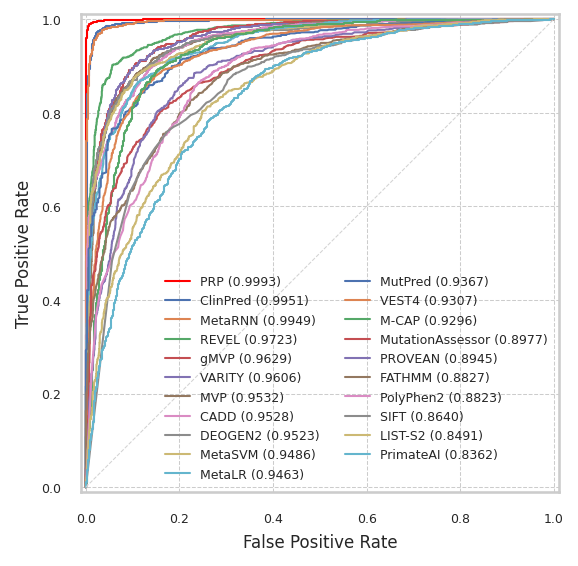

uniprot


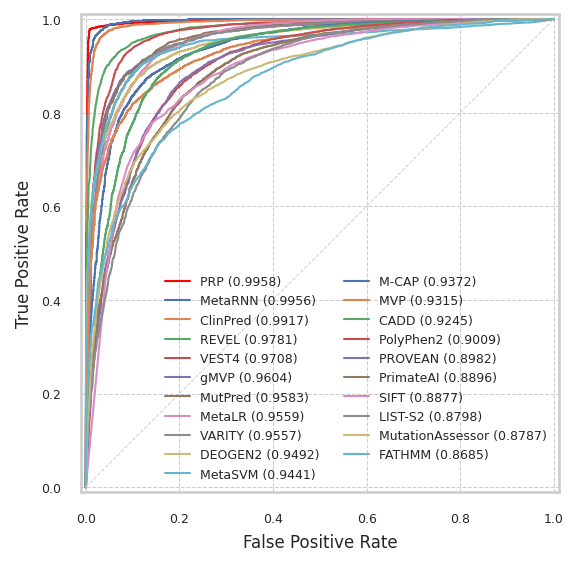

clingen


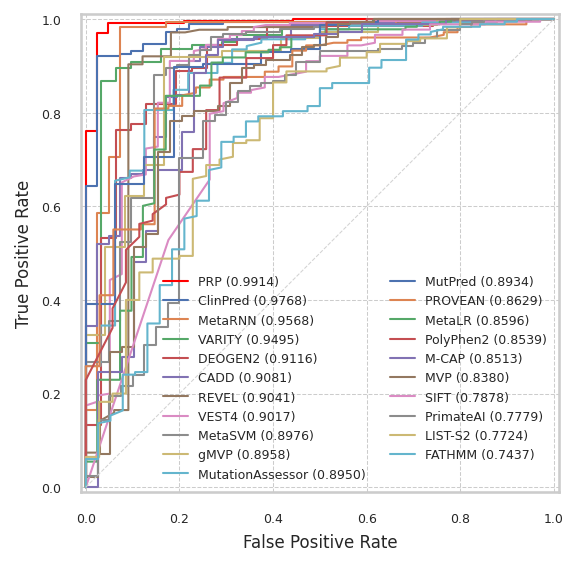

### radar: PRP

In [ ]:
def plot_radar_each(_df_result, name, png_fold):
    import plotly.express as px
    import plotly.graph_objects as go

    _df_result = _df_result.sort_values(by='AUC', ascending=False).reset_index(drop=True)

    _key = ['AUC', 'AUPRC', 'Accuracy', 'F1-score', 'MCC', 'Precision', 'Recall', 'Specificity']
    for _i, _row in _df_result.iterrows():
        _label = _row['Name']
        _value = _row[_key].values

        if _label != 'PRP':
            continue

        if _i > 5:
            continue

        _key2 = []
        for j in range(len(_value)):
            _key2.append(f'{_key[j]}<br>({_value[j]:.4f})')

        _save_png = png_fold + "/"+ f'radar_{name}_{_label}.png'
        print( _value)

        fig = px.line_polar(r = _value, theta = _key2, line_close=True, title=_label)
        #fig.update_traces(fill='toself')
        fig.update_layout(#template=None,
            polar = dict(
                    radialaxis = dict(range=[0, 1], showticklabels=True, dtick=0.1, tickfont=dict(size=12)),
                    angularaxis=dict(tickfont=dict(size=14)),
                    sector=[-270,90], radialaxis_ticks=''
                )
        )

        fig.update_layout(title_x = 0.5, title_y = 0.45, title_font_size = 20,
                    title_xanchor = "center", title_yanchor = "middle",)

        fig.update_layout(width=360,height=320,
                        margin_l=70, margin_r=70,
                        margin_b=30,margin_t=30)

        #fig.write_image(_save_png, scale=3)
        fig.show()
        #break

clinvar2
[0.9993 0.9995 0.9902 0.9915 0.98 0.9926 0.9905 0.9899]


uniprot
[0.9958 0.9949 0.9848 0.9854 0.9697 0.9923 0.9785 0.9917]


clingen
[0.9914 0.9984 0.9858 0.9916 0.9451 0.9916 0.9916 0.9535]


### dist : PRP

In [ ]:
def plot_score_dist(_df, _para, ax):
    _df = _df.copy()
    _para = _para.copy()
    _default = {'cutoff': None, 'title':None, 'y_true':None, 'y_prob':None, 'loc':None}
    _cutoff, _title,  _y_true, _y_prob, _loc = (_para.get(_k, _v) or _v for _k, _v in _default.items())

    sns.set(style="whitegrid")
    sns.kdeplot(data=_df, x = _y_prob,  hue = _y_true,
                fill=False, legend=False, ax=ax,
                )

    ax.axvline(x=_cutoff, color='r', linestyle=':',)
    ax.set_xlabel('Score', fontsize=8)
    ax.set_ylabel('Density', fontsize=8)
    ax.tick_params(axis='both', labelsize=8)
    ax.set_title(_title, fontsize = 12)
    ax.legend(labels=['Pathogenic','Benign'], fontsize=8,loc=_loc, frameon=False)
    ax.grid(linestyle='--', linewidth=0.5, )

    plt.tight_layout()
    plt.show()
    plt.close('all')


clinvar2 (4920, 119)


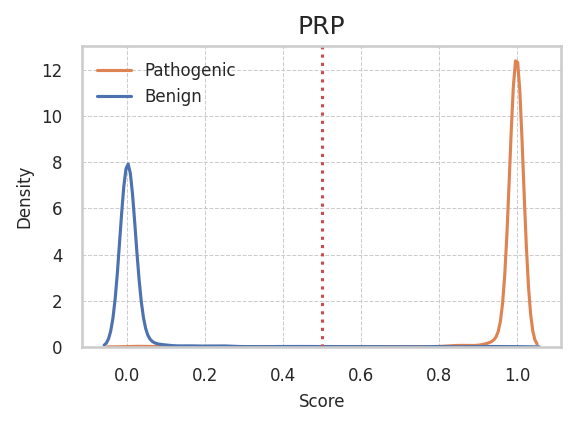

uniprot (13127, 119)


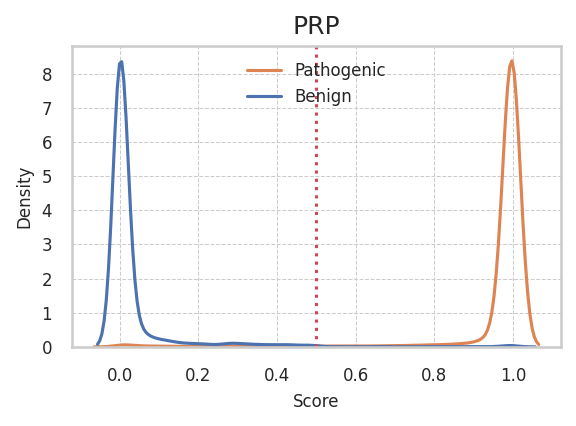

clingen (282, 119)


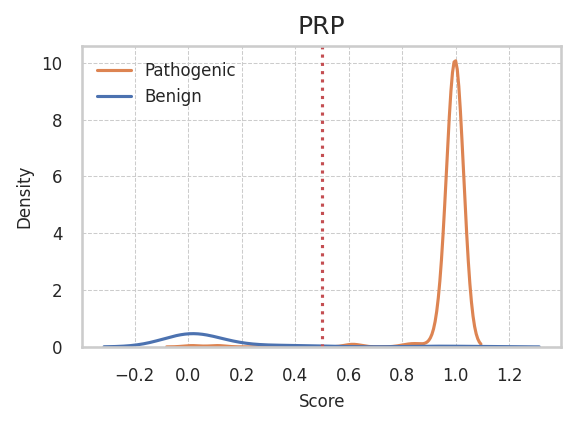

#==================================================

## Fig7: sens & spec

In [ ]:
def plot_scatter_sens_spec(_df, _title):
    _df = _df.sort_values(by=['cat', 'Name']).reset_index(drop=True)
    _n = int(_df.loc[_df['Name']=='PRP', 'N'].values[0])

    _notL = ['PolyPhen2_HDiv','SIFT4G','FATHMM-XF','FATHMM-MKL','GenoCanyon',
             'Eigen','MPC','DANN',]
    _df = _df[~(_df['Name'].isin(_notL))].reset_index(drop=True)
    _df['Name'] = _df['Name'].replace('PolyPhen2_HVar', 'PolyPhen2')

    sns.set(style="whitegrid")
    #plt.figure(figsize=(4, 4),dpi=150)
    fig, ax = plt.subplots(figsize=(4, 4), dpi=150)
    _s = 30
    sns.scatterplot(data=_df[_df['cat']==0], x="Recall", y="Specificity", style="Name", color='red', s=_s)
    sns.scatterplot(data=_df[_df['cat']==1], x="Recall", y="Specificity", style="Name", s=_s)
    sns.scatterplot(data=_df[_df['cat']==2], x="Recall", y="Specificity", style="Name", s=_s)

    plt.xlim(-0.01, 1.01)
    plt.ylim(-0.01, 1.01)
    #plt.legend(bbox_to_anchor=(1, 1.01), loc='upper left',frameon=False, fontsize=6)
    legend = plt.legend(ncol=3, loc='lower left',frameon=False, fontsize=5.5)
    #legend.get_frame().set_facecolor('white')  # Set background color to white
    #legend.get_frame().set_edgecolor('white')  # Optionally, set border color
    #legend.get_frame().set_alpha(0.1)  # Make the background fully opaque


    #plt.title(f'{_title} (N={_n:,})', fontsize=12)
    plt.grid(linestyle='--',linewidth=0.5)
    #plt.gca().xaxis.set_major_locator(plt.MultipleLocator(0.1))
    #plt.gca().yaxis.set_major_locator(plt.MultipleLocator(0.1))
    plt.axvline(x=0.8, color='red', linestyle='--', linewidth=0.5)
    plt.axhline(y=0.8, color='red', linestyle='--', linewidth=0.5)
    plt.xlabel('Sensitivity', fontsize=8)
    plt.ylabel('Specificity', fontsize=8)
    plt.xticks([0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0],fontsize=6)
    plt.yticks([0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0],fontsize=6)
    ax.set_aspect('equal', adjustable='box')  # 축 비율을 정사각형으로 맞춤
    plt.show()

    #display(_df)


clinvar2


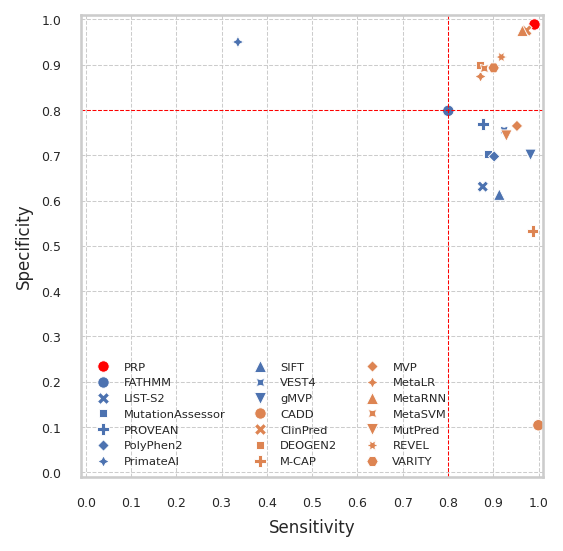

uniprot


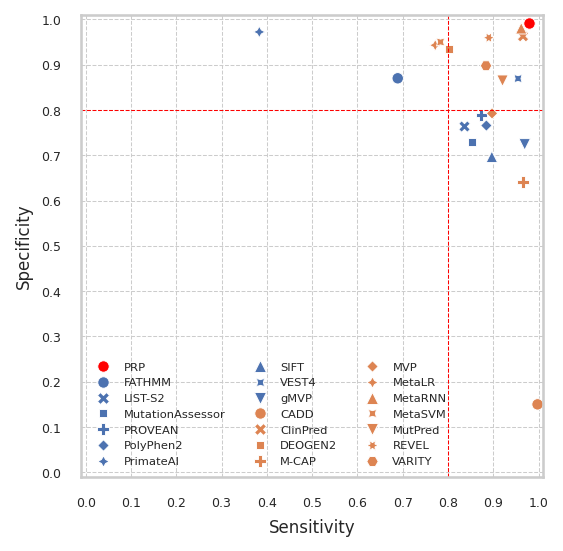

clingen


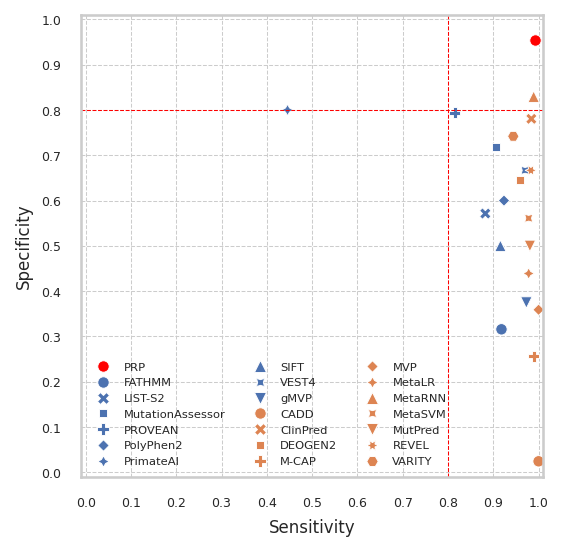

#==================================================

## Fig 8: AF performance comparison

In [ ]:
def plot_scatter_sens_spec_auc_3d(_df, _afD, _colL):
    from mpl_toolkits.mplot3d import Axes3D
    from itertools import cycle
    sns.set(style="whitegrid")

    _df = _df.sort_values(['AF','AUC'],ascending=False).reset_index(drop=True)
    _df['AF'] = _df['AF'].replace(_afD)
    _toolL = _df['Name'].unique()
    _afL = _df['AF'].unique()
    # 색상 및 마커 리스트
    _cL = plt.cm.tab10.colors  # 10가지 기본 색상
    _mL = ['o', 's', '^', 'D', 'P', '*', 'X', 'v', '<', '>']

    # 색상과 마커를 순환적으로 사용
    _cCycle = cycle(_cL)
    _mCycle = cycle(_mL)

    # d컬럼의 고유값에 따라 색상을 매핑
    _cMap = {_tool: next(_cCycle) for _tool in _toolL}

    # e컬럼의 고유값에 따라 마커를 매핑
    _mMap = {_af: next(_mCycle) for _af in _afL}

    # 3D 플롯 설정
    fig = plt.figure(figsize=(3, 3), dpi=150)
    ax = fig.add_subplot(111, projection='3d')

    # 데이터 그룹별로 분리하여 플롯
    for _tool in _toolL:
        for _af in _afL:
            _tmp = _df[(_df['Name'] == _tool) & (_df['AF'] == _af)]
            ax.scatter(_tmp[_colL[0]], _tmp[_colL[1]], _tmp[_colL[2]],
                       color=_cMap[_tool], marker=_mMap[_af], s=10)

    _cLegend = [
        plt.Line2D([0], [0], marker='o', color=_cMap[_tool],
                   linestyle='', label=_tool)
        for _tool in _toolL
    ]

    _mLegend = [
        plt.Line2D([0], [0], marker=_mMap[_af], color='gray',
                   linestyle='', label=_af)
        for _af in _afL
    ]

    # 범례 추가
    legend = ax.legend(handles=_cLegend,
                        loc='lower left', ncol=1, fontsize=6, frameon=False,
                        bbox_to_anchor=(0.05, 0.22), markerscale=0.5)
    ax.add_artist(legend)
    legend2 = ax.legend(handles=_mLegend,
                        loc='lower left', ncol=1, fontsize=6, frameon=False,
                        bbox_to_anchor=(0.3, 0.22), markerscale=0.5,)
    ax.add_artist(legend2)


    # 축 레이블
    ax.set_xlabel(_colL[0], fontsize=8)
    ax.set_ylabel(_colL[1], fontsize=8)
    ax.set_zlabel(_colL[2], fontsize=8)  # 회전각도를 90도로 설정

    _x, _y, _z, _w = 0.8, 1.0, 5, 0.05
    if _df[_colL[0]].min()<0.8 or _df[_colL[1]].min()<0.8 or _df[_colL[2]].min()<0.8:
        _x, _y, _z, _w = 0.6, 1.0, 5, 0.1

    ax.set_xlim(_x, _y)
    ax.set_ylim(_x, _y)
    ax.set_zlim(_x, _y)

    _range = [i * _w + _x for i in range(_z)]
    plt.xticks(_range,fontsize=6)
    plt.yticks(_range,fontsize=6)
    ax.set_zticks(_range)  # 0.8부터 1까지 0.05 단위로 설정
    ax.set_zticklabels([f'{i:.2f}' for i in ax.get_zticks()], fontsize=6)

    ax.xaxis._axinfo['grid'].update(linewidth=0.5, linestyle="--")
    ax.yaxis._axinfo['grid'].update(linewidth=0.5, linestyle="--")
    ax.zaxis._axinfo['grid'].update(linewidth=0.5, linestyle="--")

    plt.show()
    #display(_df)

clinvar2


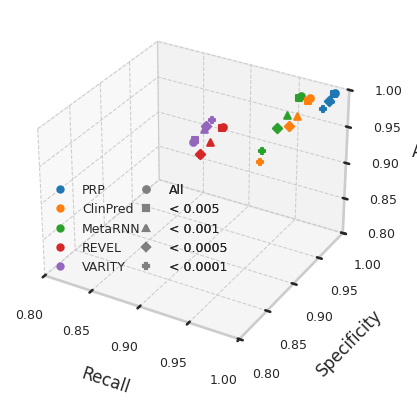

uniprot


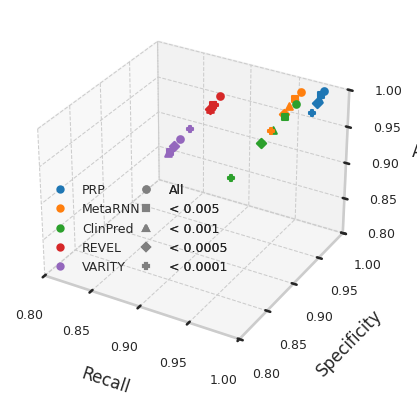

clingen


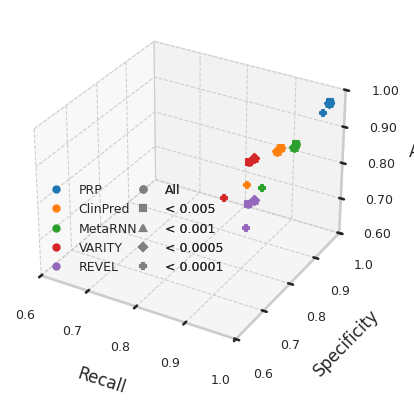

#==================================================

## Fig S3: radar plot: tool comparison

In [ ]:
def plot_radar_test_multi(df,_name):
    import plotly.express as px
    import plotly.graph_objects as go

    #_color = ['#EF553B','#00CC96','#AB63FA', '#FFA15A',]
    _color = ['#00CC96','#AB63FA', '#FFA15A',]
    legend_name = 'Dataset'
    _theta=['AUC', 'AUPRC', 'Accuracy', 'F1-score', 'MCC', 'Precision', 'Recall', 'Specificity']

    fig = px.line_polar(df, r='r', color=legend_name, theta='theta', line_close=True,
                        color_discrete_sequence=_color,title=_name
                        #color_discrete_sequence=px.colors.qualitative.Light24,
                        )
    fig.update_layout(#template=None,
        polar = dict(radialaxis = dict(range=[0, 1], showticklabels=True, dtick=0.1),
                    angularaxis=dict(tickfont=dict(size=16)),)
        )
    fig.update_polars(sector=[-270,90], radialaxis_ticks='')
    #fig.update_layout(title_text='B',
    #                title_x = 0.05, title_y = 0.95, title_font_size = 16,
    #                title_xanchor = "center", title_yanchor = "middle")
    fig.update_layout(width=530,height=440,
                        margin_l=60, margin_r=80,
                        margin_b=30,margin_t=30)
    fig.update_layout(title_x = 0.47, title_y = 0.45, title_font_size = 20,
                    title_xanchor = "center", title_yanchor = "middle",)


    _save_png = fold_here + f'/radar_compare_dataset.png'
    #print("!!! png: ", _save_png)
    #fig.write_image(_save_png, scale=3)
    fig.show()

<ipython-input-232-ea16c2bcad99>:5: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



#==================================================